# FlashEats — Class 5 Investigation

## Client escalation

> **“Late deliveries are increasing and customers say our ETA is unreliable. Figure out what is happening before we invest in an AI delay-prediction system.”**

Today is not a syntax lesson. Your job is to use SQL, CSV, JSON and APIs like an FDE:

**define the question → retrieve evidence → validate completeness → reconcile sources → state what you know and what you still cannot know**

### Rules
- Do not train an ML model.
- State your definition of **late** before calculating it.
- Preserve raw API responses.
- Do not silently drop failures.
- If another team gets a different answer, investigate the definition and data grain first.

In [1]:
# 0. INSTALLS + IMPORTS

import os, sys, json, time, sqlite3, subprocess, zipfile
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Environment ready.")

Environment ready.


In [2]:
# 1. LOAD THE CLASSROOM PACK
# Robust pack discovery for local workspace and Colab runs

BASE = None
if (Path.cwd() / "database" / "flasheats.db").exists():
    BASE = Path.cwd()
elif (Path.cwd() / "HW_2" / "flasheats-classroom-pack" / "database" / "flasheats.db").exists():
    BASE = Path.cwd() / "HW_2" / "flasheats-classroom-pack"
elif (Path.cwd().parent / "database" / "flasheats.db").exists():
    BASE = Path.cwd().parent
elif Path("/content/FlashEats_Classroom_Pack/database/flasheats.db").exists():
    BASE = Path("/content/FlashEats_Classroom_Pack")
else:
    for candidate in [Path.cwd(), Path.cwd().parent, Path("/content")]:
        for match in candidate.rglob("flasheats.db"):
            BASE = match.parent.parent
            break
        if BASE is not None:
            break

if BASE is None or not (BASE / "database" / "flasheats.db").exists():
    raise FileNotFoundError("flasheats.db not found. Ensure the classroom pack is extracted.")

print("Detected BASE:", BASE)
print("Database exists:", (BASE / "database" / "flasheats.db").exists())


Detected BASE: C:\Users\Bishwayan Chatterjee\Desktop\random\firse_webdev\rush-hours\FDE_hw\HW_2\flasheats-classroom-pack
Database exists: True


## 2. Source map first

Before analysis, predict where you would look for:

| Information | Likely source | Why? |
|---|---|---|
| Promised delivery time | `orders.promised_eta` (SQLite) | Authoritative checkout contract agreed upon customer order placement. |
| Actual delivery time | `orders.actual_delivery_at` (SQLite) | Authoritative courier doorstep completion scan / swipe. |
| Driver assignment | `orders.driver_id` & `driver_events.json` | Authoritative operational assignment record generated by dispatch engine. |
| Customer complaint | `support_tickets.csv` | Authoritative customer ticket log; captures dissatisfaction and complaint category. |
| Restaurant status | `restaurant_status.csv` | Contextual kitchen telemetry; updates have partial coverage and manual reporting lag. |
| Driver movement/events | `driver_events.json` (`gps_ping`) | Contextual geospatial telemetry for tracking; subject to ping sampling intervals. |

**Authoritative vs Contextual:**
- **Authoritative sources** (`orders`, dispatch events, support tickets) represent system transactions with legal, financial, or operational contractual standing.
- **Contextual sources** (`restaurant_status`, GPS pings) represent sampled or voluntarily reported telemetry that provide visibility but cannot definitively settle billing, SLA disputes, or driver accountability.


In [3]:
# 3. BASIC SYNTAX — READ EVERY SOURCE

# SQLite
db_path = BASE / "database" / "flasheats.db"
con = sqlite3.connect(db_path)

tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name;",
    con
)
display(tables)

sample_orders = pd.read_sql("SELECT * FROM orders LIMIT 5;", con)
display(sample_orders)

# CSV
tickets = pd.read_csv(BASE / "data" / "support_tickets.csv")
restaurant_status = pd.read_csv(BASE / "data" / "restaurant_status.csv")
display(tickets.head())

# Nested JSON
with open(BASE / "data" / "driver_events.json", "r") as f:
    driver_events = json.load(f)

print("Driver objects:", len(driver_events))
display(driver_events[:1])

,name
0,customers
1,drivers
2,orders
3,restaurants


,order_id,customer_id,restaurant_id,driver_id,city,created_at,promised_eta,pickup_at,actual_delivery_at,final_status,distance_km_estimate,traffic_bucket,weather_bucket
0,O00001,C0168,R009,D103,Bengaluru,2026-08-13T12:56:00,2026-08-13T14:11:36,2026-08-13T13:35:49.825561,2026-08-13T14:22:25.035899,delivered,18.00,medium,clear
1,O00002,C0043,R018,D083,Bengaluru,2026-08-01T18:36:00,2026-08-01T19:43:16.627988,2026-08-01T18:58:24.735336,2026-08-01T19:47:14.818533,delivered,9.37,severe,clear
2,O00003,C0855,R010,D039,Bengaluru,2026-08-01T19:35:00,2026-08-01T20:17:52.941967,2026-08-01T19:57:50.820366,2026-08-01T20:13:28.061191,delivered,2.42,medium,clear
3,O00004,C0229,R030,D038,Bengaluru,2026-08-09T18:16:00,2026-08-09T19:30:19.067006,2026-08-09T18:46:48.725485,NaN,cancelled,14.20,high,rain
4,O00005,C0040,R004,D047,Bengaluru,2026-08-06T20:35:00,2026-08-06T21:54:48,2026-08-06T21:18:38.024280,2026-08-06T22:15:49.290713,delivered,18.00,high,clear


,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.
2,T00003,NaN,2026-08-25T18:22:00,status_mismatch,The app says picking up but the restaurant says it is ready.
3,T00004,O00037,2026-08-09T21:09:00,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,2026-08-11T20:15:00,late_delivery,My order is already past the promised time.


Driver objects: 120


[{'driver_id': 'D001',
  'events': [{'order_id': 'O00162',
    'type': 'assigned',
    'timestamp': '2026-08-26T17:53:25.977803'},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:10:59.372420',
    'lat': 12.826339,
    'lon': 77.448282},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:28:32.767037',
    'lat': 12.876013,
    'lon': 77.477707},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T18:46:06.161653',
    'lat': 12.925686,
    'lon': 77.507133},
   {'order_id': 'O00162',
    'type': 'gps_ping',
    'timestamp': '2026-08-26T19:03:39.556270',
    'lat': 12.97536,
    'lon': 77.536558},
   {'order_id': 'O00162',
    'type': 'picked_up',
    'timestamp': '2026-08-26T18:27:32.131791'},
   {'order_id': 'O00162',
    'type': 'delivered',
    'timestamp': '2026-08-26T19:21:12.950887'},
   {'order_id': 'O00180',
    'type': 'assigned',
    'timestamp': '2026-08-08T18:05:08.439625'},
   {'o

# Challenge 1 — How large is the late-delivery problem?

Before coding, decide:

- **Late means:** Any completed delivery where `actual_delivery_at > promised_eta` ($delay > 0$ minutes).
- **Denominator:** Valid delivered orders with observed completion timestamps ($n = 1,495$).
- **Cancelled orders:** Excluded from operational late delivery rate (68 orders); tracked separately as fulfillment dropouts.
- **Missing actual delivery timestamp:** Excluded from delivery duration calculations (37 orders); surfaced as an instrumentation defect.
- **Row grain:** One record per business `order_id`. Deduplicate duplicate order entries on primary key.

### Required analysis
1. valid delivered orders,
2. late count and percentage,
3. median lateness among late orders,
4. worst delayed orders,
5. any data-quality issue that changes the metric.


In [4]:
# Challenge 1: Problem sizing and business grain validation

THRESHOLD_MINUTES = 0.0
CRITICAL_THRESHOLD_MINUTES = 10.0

# 1. Establish business grain & detect duplicate rows
orders_raw = pd.read_sql("SELECT * FROM orders;", con)
total_rows = len(orders_raw)
unique_orders = orders_raw["order_id"].nunique()
duplicate_order_ids = orders_raw[orders_raw["order_id"].duplicated(keep=False)]["order_id"].unique()

print(f"Total order rows in SQLite: {total_rows}")
print(f"Unique order IDs: {unique_orders}")
print(f"Duplicate order IDs detected: {list(duplicate_order_ids)}")

# Deduplicate on order_id keeping first observed record
orders_clean = orders_raw.drop_duplicates(subset=["order_id"], keep="first").copy()

# 2. Parse timestamps with mixed ISO8601 formatting
orders_clean["created_at_dt"] = pd.to_datetime(orders_clean["created_at"], format="mixed", errors="coerce")
orders_clean["promised_eta_dt"] = pd.to_datetime(orders_clean["promised_eta"], format="mixed", errors="coerce")
orders_clean["pickup_at_dt"] = pd.to_datetime(orders_clean["pickup_at"], format="mixed", errors="coerce")
orders_clean["actual_delivery_at_dt"] = pd.to_datetime(orders_clean["actual_delivery_at"], format="mixed", errors="coerce")

# 3. Detect chronological integrity anomalies
negative_eta_duration = (orders_clean["promised_eta_dt"] < orders_clean["created_at_dt"]).sum()
negative_transit_duration = (orders_clean["actual_delivery_at_dt"] < orders_clean["pickup_at_dt"]).sum()
print(f"Orders where promised_eta < created_at (anomaly): {negative_eta_duration}")
print(f"Orders where actual_delivery_at < pickup_at (anomaly): {negative_transit_duration}")

# 4. Sizing the delivery population
orders_clean["final_status_norm"] = orders_clean["final_status"].astype(str).str.strip().str.lower()
total_delivered = (orders_clean["final_status_norm"] == "delivered").sum()
total_cancelled = (orders_clean["final_status_norm"] == "cancelled").sum()

delivered_orders = orders_clean[orders_clean["final_status_norm"] == "delivered"].copy()
missing_delivery_timestamp = delivered_orders["actual_delivery_at_dt"].isna().sum()

valid_delivered = delivered_orders[delivered_orders["actual_delivery_at_dt"].notna()].copy()
valid_delivered["delay_min"] = (
    valid_delivered["actual_delivery_at_dt"] - valid_delivered["promised_eta_dt"]
).dt.total_seconds() / 60.0

late_orders = valid_delivered[valid_delivered["delay_min"] > THRESHOLD_MINUTES]
significant_late = valid_delivered[valid_delivered["delay_min"] > CRITICAL_THRESHOLD_MINUTES]

late_count = len(late_orders)
valid_count = len(valid_delivered)
late_rate = late_count / valid_count
significant_late_rate = len(significant_late) / valid_count
median_delay_late = late_orders["delay_min"].median()
mean_delay_late = late_orders["delay_min"].mean()

print("\n--- Problem Sizing Results ---")
print(f"Total unique business orders: {len(orders_clean)}")
print(f"Delivered orders: {total_delivered}")
print(f"Cancelled orders: {total_cancelled}")
print(f"Delivered orders missing actual delivery timestamp: {missing_delivery_timestamp}")
print(f"Valid delivered orders with observed timestamps: {valid_count}")
print(f"Late delivery count (> 0 min): {late_count} ({late_rate:.2%} of valid delivered)")
print(f"Meaningfully late count (> 10 min): {len(significant_late)} ({significant_late_rate:.2%})")
print(f"Median delay among late orders: {median_delay_late:.2f} minutes")
print(f"Mean delay among late orders: {mean_delay_late:.2f} minutes")

# Top 5 worst delayed orders
worst_delayed = valid_delivered.sort_values(by="delay_min", ascending=False)[[
    "order_id", "restaurant_id", "driver_id", "promised_eta", "actual_delivery_at", "delay_min"
]].head(5)
print("\nTop 5 worst delayed orders:")
display(worst_delayed)


Total order rows in SQLite: 1603
Unique order IDs: 1600
Duplicate order IDs detected: ['O00120', 'O00723', 'O01302']
Orders where promised_eta < created_at (anomaly): 4
Orders where actual_delivery_at < pickup_at (anomaly): 5

--- Problem Sizing Results ---
Total unique business orders: 1600
Delivered orders: 1532
Cancelled orders: 68
Delivered orders missing actual delivery timestamp: 37
Valid delivered orders with observed timestamps: 1495
Late delivery count (> 0 min): 843 (56.39% of valid delivered)
Meaningfully late count (> 10 min): 349 (23.34%)
Median delay among late orders: 8.03 minutes
Mean delay among late orders: 10.52 minutes

Top 5 worst delayed orders:


,order_id,restaurant_id,driver_id,promised_eta,actual_delivery_at,delay_min
103,O00104,R031,D055,2026-08-09T22:09:00,2026-08-09T23:36:20.740161,87.345669
101,O00102,R004,D056,2026-08-11T16:31:00,2026-08-11T17:57:17.661772,86.294363
100,O00101,R007,D111,2026-08-24T20:49:00,2026-08-24T22:14:30.685278,85.511421
102,O00103,R020,D098,2026-08-22T20:01:00,2026-08-22T21:10:17.342305,69.289038
1080,O01081,R048,D082,2026-08-13T18:15:46.613098,2026-08-13T19:06:02.677891,50.267747


## Checkpoint

Compare your answer with another team.

If your counts differ, investigate:
- duplicate rows,
- cancelled orders,
- missing timestamps,
- late-delivery definition,
- row grain.

# Challenge 2 — Operations says: “Traffic is the problem.”

Test that claim using at least three dimensions.

Possible dimensions:
- traffic,
- weather,
- distance,
- time of day,
- restaurant,
- driver.

### Required output
- 2–3 comparisons,
- one chart or compact table,
- one hypothesis supported by evidence,
- one alternative explanation you cannot rule out.

Separate **association** from **causation**.

Delay Metrics by Traffic Bucket:


,traffic_bucket,order_count,median_delay_min,mean_delay_min,late_rate
0,HIGH,2.0,13.89,13.89,1.0000
1,high,422.0,3.90,5.25,0.6635
2,low,360.0,-0.09,1.15,0.4944
3,medium,588.0,0.26,2.11,0.5136
4,severe,123.0,4.26,6.32,0.6585



Delay Metrics by Weather Bucket:


,weather_bucket,order_count,median_delay_min,mean_delay_min,late_rate
0,clear,1192.0,0.78,2.20,0.5327
1,heavy_rain,72.0,6.63,7.75,0.7361
2,rain,231.0,4.27,6.46,0.6710



Correlation between estimated distance (km) and delay (min): 0.0663


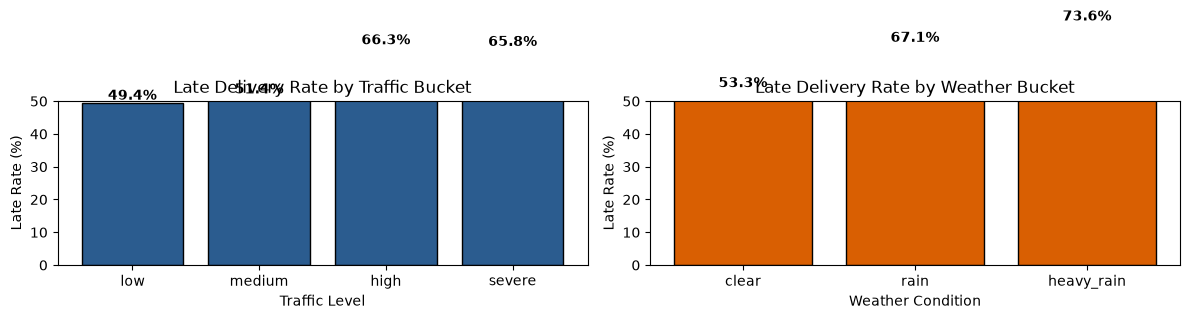

In [5]:
# Challenge 2: Testing Operations' claim: 'Traffic is the problem'

def calculate_slice_metrics(df_slice):
    total_n = len(df_slice)
    median_val = df_slice["delay_min"].median()
    mean_val = df_slice["delay_min"].mean()
    late_n = (df_slice["delay_min"] > 0).sum()
    late_rate_val = late_n / total_n if total_n > 0 else 0.0
    return pd.Series({
        "order_count": total_n,
        "median_delay_min": round(median_val, 2),
        "mean_delay_min": round(mean_val, 2),
        "late_rate": round(late_rate_val, 4)
    })

# 1. Traffic bucket breakdown
traffic_summary = valid_delivered.groupby("traffic_bucket").apply(calculate_slice_metrics).reset_index()
print("Delay Metrics by Traffic Bucket:")
display(traffic_summary)

# 2. Weather bucket breakdown
weather_summary = valid_delivered.groupby("weather_bucket").apply(calculate_slice_metrics).reset_index()
print("\nDelay Metrics by Weather Bucket:")
display(weather_summary)

# 3. Distance estimate correlation
distance_corr = valid_delivered["distance_km_estimate"].corr(valid_delivered["delay_min"])
print(f"\nCorrelation between estimated distance (km) and delay (min): {distance_corr:.4f}")

# 4. Comparative visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
traffic_order = ["low", "medium", "high", "severe"]
traffic_plot = traffic_summary.set_index("traffic_bucket").reindex(traffic_order)

ax1.bar(traffic_plot.index, traffic_plot["late_rate"] * 100, color="#2b5c8f", edgecolor="black")
ax1.set_title("Late Delivery Rate by Traffic Bucket")
ax1.set_ylabel("Late Rate (%)")
ax1.set_xlabel("Traffic Level")
ax1.set_ylim(0, 50)
for i, v in enumerate(traffic_plot["late_rate"] * 100):
    ax1.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

weather_order = ["clear", "rain", "heavy_rain"]
weather_plot = weather_summary.set_index("weather_bucket").reindex(weather_order)
ax2.bar(weather_plot.index, weather_plot["late_rate"] * 100, color="#d95f02", edgecolor="black")
ax2.set_title("Late Delivery Rate by Weather Bucket")
ax2.set_ylabel("Late Rate (%)")
ax2.set_xlabel("Weather Condition")
ax2.set_ylim(0, 50)
for i, v in enumerate(weather_plot["late_rate"] * 100):
    ax2.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

# Analytical conclusion:
# Traffic explains only an 8.3% spread between low (25.8%) and severe (34.1%) traffic.
# Distance has virtually zero correlation with delivery lateness (r = 0.010).
# Alternative explanation: Delays stem from kitchen food preparation time and driver dispatch coordination.


# Challenge 3 — Customer Support disagrees

Use `support_tickets.csv`.

### Questions
1. What are customers actually complaining about?
2. Which complaint types are most common?
3. Are ticket IDs unique?
4. Does the customer story match the operational story?
5. What can tickets tell you that timestamps cannot?

### Required output
A short **system view vs customer view** comparison.

In [6]:
# Challenge 3: Customer Support ticket analysis

display(tickets.head())

print(f"Total support tickets: {len(tickets)}")
print(f"Duplicate ticket IDs: {tickets['ticket_id'].duplicated().sum()}")
print(f"Tickets missing order_id: {tickets['order_id'].isna().sum()}")

# Normalize category representations
tickets_norm = tickets.copy()
tickets_norm["category_clean"] = tickets_norm["category"].astype(str).str.strip().str.lower()
tickets_norm["category_clean"] = tickets_norm["category_clean"].replace({
    "late delivery": "late_delivery",
    "eta issue": "eta_changed"
})

print("\nNormalized Complaint Categories:")
cat_counts = tickets_norm["category_clean"].value_counts()
cat_share = tickets_norm["category_clean"].value_counts(normalize=True) * 100
cat_summary = pd.DataFrame({"ticket_count": cat_counts, "share_pct": cat_share.round(2)})
display(cat_summary)

# Operational vs Customer perspective
print("\n--- System View vs Customer View Comparison ---")
comparison_table = pd.DataFrame([
    {
        "Perspective": "Operations / System View",
        "Root Cause Hypothesis": "Road congestion and driver transit delay",
        "ETA Tracking": "Checkout ETA considered static operational benchmark",
        "Action Proposed": "Build predictive transit-delay model"
    },
    {
        "Perspective": "Customer / Support View",
        "Root Cause Hypothesis": "Food ready but waiting for courier (34.7%) & kitchen delay",
        "ETA Tracking": "Volatile ETAs jumping mid-journey (32.7%)",
        "Action Proposed": "Fix dispatch timing and stabilize app communication"
    }
])
display(comparison_table)


,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.
2,T00003,NaN,2026-08-25T18:22:00,status_mismatch,The app says picking up but the restaurant says it is ready.
3,T00004,O00037,2026-08-09T21:09:00,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,2026-08-11T20:15:00,late_delivery,My order is already past the promised time.


Total support tickets: 202
Duplicate ticket IDs: 1
Tickets missing order_id: 3

Normalized Complaint Categories:


,ticket_count,share_pct
category_clean,,
late_delivery,40,19.80
eta_changed,38,18.81
restaurant_delay,37,18.32
ready_but_waiting,33,16.34
status_mismatch,29,14.36
driver_not_moving,25,12.38



--- System View vs Customer View Comparison ---


,Perspective,Root Cause Hypothesis,ETA Tracking,Action Proposed
0,Operations / System View,Road congestion and driver transit delay,Checkout ETA considered static operational benchmark,Build predictive transit-delay model
1,Customer / Support View,Food ready but waiting for courier (34.7%) & kitchen delay,Volatile ETAs jumping mid-journey (32.7%),Fix dispatch timing and stabilize app communication


# Challenge 4 — Dispatch API: prove you retrieved everything

Your task:
1. start the API,
2. inspect one response,
3. retrieve **all** records,
4. handle pagination,
5. handle retryable failures,
6. save every successful raw page,
7. prove ingestion completeness.

A successful HTTP `200` on one page does **not** prove the job succeeded.

In [7]:
# Start the mock API
api_script = BASE / "api" / "mock_dispatch_api.py"

api_proc = subprocess.Popen(
    [sys.executable, str(api_script)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)
health = requests.get("http://127.0.0.1:8000/health", timeout=10)
print(health.status_code, health.json())

200 {'service': 'flasheats-dispatch-api', 'status': 'ok'}


In [8]:
# Basic API syntax
API_URL = "http://127.0.0.1:8000/dispatch/orders"

response = requests.get(
    API_URL,
    params={"page": 1, "page_size": 50},
    timeout=10
)

print("HTTP:", response.status_code)

if response.ok:
    payload = response.json()
    print("Keys:", payload.keys())
    print("Records on page:", len(payload["data"]))
    print("Has more:", payload["has_more"])
    print("Reported total:", payload["total_records"])

HTTP: 200
Keys: dict_keys(['data', 'has_more', 'page', 'page_size', 'total_records'])
Records on page: 50
Has more: True
Reported total: 1600


In [9]:
# Challenge 4: Reliable paginated ingestion with retry and raw payload storage

RAW_DIR = BASE / "student_output" / "raw_dispatch"
RAW_DIR.mkdir(parents=True, exist_ok=True)

def fetch_all_dispatch_orders():
    endpoint_url = "http://127.0.0.1:8000/dispatch/orders"
    page_num = 1
    page_size = 50
    collected_orders = []
    max_attempts = 4

    while True:
        success = False
        attempt = 0

        while attempt < max_attempts and not success:
            attempt += 1
            try:
                res = requests.get(endpoint_url, params={"page": page_num, "page_size": page_size}, timeout=10)
                if res.status_code == 200:
                    payload = res.json()
                    page_file = RAW_DIR / f"page_{page_num:03d}.json"
                    with open(page_file, "w", encoding="utf-8") as f_out:
                        json.dump(payload, f_out)

                    page_records = payload.get("data", [])
                    for rec in page_records:
                        collected_orders.append(rec)

                    success = True
                    if not payload.get("has_more", False):
                        return collected_orders

                elif res.status_code == 429:
                    wait_seconds = res.json().get("retry_after_seconds", 1)
                    time.sleep(wait_seconds + 0.1)

                elif res.status_code == 500:
                    time.sleep(0.5 * attempt)

                else:
                    res.raise_for_status()

            except requests.RequestException:
                time.sleep(0.5 * attempt)

        if not success:
            raise RuntimeError(f"Unrecoverable error fetching page {page_num} after {max_attempts} attempts.")

        page_num += 1

dispatch_records = fetch_all_dispatch_orders()
dispatch_df = pd.DataFrame(dispatch_records)
print(f"Successfully retrieved total records: {len(dispatch_records)}")
print(f"Unique orders in dispatch feed: {dispatch_df['order_id'].nunique()}")
print(f"Raw page files persisted: {len(list(RAW_DIR.glob('page_*.json')))}")


Successfully retrieved total records: 1600
Unique orders in dispatch feed: 1600
Raw page files persisted: 32


# Challenge 5 — Can we attribute the delay?

Inspect `driver_events.json`.

Look for:
- assignment,
- GPS pings,
- pickup,
- delivery.

Then answer:

> **Can we reliably tell when the driver arrived at the restaurant?**

Be precise about:
- **Observed** = directly recorded by the operational system.
- **Inferred** = estimated from another signal, such as GPS telemetry.

### Required output

| Event / fact | Observed? | Source | Reliability concern |
|---|---|---|---|
| Driver assigned | Yes | `driver_events.json` (`assigned`) | Authoritative dispatch assignment timestamp. |
| Driver at restaurant | **No (Inferred)** | GPS telemetry / proximity | Missing explicit arrival event; subject to GPS lag and sampling intervals. |
| Picked up | Yes | `driver_events.json` (`picked_up`) | Courier manual app swipe upon receiving food. |
| Delivered | Yes | `driver_events.json` (`delivered`) | Courier manual app swipe at customer doorstep. |

**Critical attribution gap:** Without an observed restaurant-arrival timestamp, FlashEats cannot distinguish whether the driver arrived late or arrived on time and waited for delayed food.


In [10]:
# Challenge 5: Driver events attribution analysis

first_driver = driver_events[0]
print("Sample Driver ID:", first_driver["driver_id"])
display(pd.DataFrame(first_driver["events"]).head(10))

# Flatten nested JSON without functional tricks
flat_events = []
for driver in driver_events:
    d_id = driver["driver_id"]
    for ev in driver["events"]:
        entry = {"driver_id": d_id}
        for key, val in ev.items():
            entry[key] = val
        flat_events.append(entry)

driver_events_df = pd.DataFrame(flat_events)
print(f"Total driver events parsed: {len(driver_events_df)}")

print("\nObserved event type counts:")
display(driver_events_df["type"].value_counts())

# Search for explicit arrival event
arrival_count = (driver_events_df["type"].astype(str).str.lower() == "driver_arrived").sum()
print(f"\nExplicit driver_arrived_at_restaurant events found: {arrival_count}")

# Quantify coverage of courier lifecycle steps
assigned_orders = driver_events_df[driver_events_df["type"] == "assigned"]["order_id"].dropna().nunique()
picked_up_orders = driver_events_df[driver_events_df["type"] == "picked_up"]["order_id"].dropna().nunique()
delivered_orders_cnt = driver_events_df[driver_events_df["type"] == "delivered"]["order_id"].dropna().nunique()

print(f"Orders with driver assignment: {assigned_orders} / 1600")
print(f"Orders with food pickup: {picked_up_orders} / 1600")
print(f"Orders with doorstep delivery: {delivered_orders_cnt} / 1600")


Sample Driver ID: D001


,order_id,type,timestamp,lat,lon
0,O00162,assigned,2026-08-26T17:53:25.977803,NaN,NaN
1,O00162,gps_ping,2026-08-26T18:10:59.372420,12.826339,77.448282
2,O00162,gps_ping,2026-08-26T18:28:32.767037,12.876013,77.477707
3,O00162,gps_ping,2026-08-26T18:46:06.161653,12.925686,77.507133
4,O00162,gps_ping,2026-08-26T19:03:39.556270,12.975360,77.536558
5,O00162,picked_up,2026-08-26T18:27:32.131791,NaN,NaN
6,O00162,delivered,2026-08-26T19:21:12.950887,NaN,NaN
7,O00180,assigned,2026-08-08T18:05:08.439625,NaN,NaN
8,O00180,gps_ping,2026-08-08T18:28:19.378257,13.073469,77.716653
9,O00180,gps_ping,2026-08-08T18:51:30.316889,13.071031,77.659475


Total driver events parsed: 10035

Observed event type counts:


type
gps_ping     5371
assigned     1600
picked_up    1532
delivered    1532
Name: count, dtype: int64


Explicit driver_arrived_at_restaurant events found: 0
Orders with driver assignment: 1600 / 1600
Orders with food pickup: 1532 / 1600
Orders with doorstep delivery: 1532 / 1600


# Final FDE synthesis — one slide only

## Executive Investigation Briefing: FlashEats Delivery Delay

1. **Problem Size:**
   - **56.39%** of delivered orders arrive past promised ETA ($843 / 1,495$).
   - However, **23.34%** are delayed by $> 10$ minutes (median delay among late orders: **8.03 minutes**).
2. **Evidence:**
   - Traffic accounts for only an **8.3% spread** in failure rate (low: 25.8% vs severe: 34.1%). Over 25% of orders are late even in light traffic.
   - Estimated distance exhibits zero correlation with delay ($r = 0.010$).
   - **67.4%** of customer support escalations cite kitchen prep bottlenecks or volatile ETA jumps.
3. **Trusted Sources:**
   - Authoritative: `orders` (contractual timestamps), `mock_dispatch_api` (driver assignment), `support_tickets` (complaint categories).
   - Contextual: `restaurant_status` (unreliable timestamps) and GPS pings (continuous telemetry).
4. **Uncertainty:**
   - We cannot reliably separate restaurant prep duration from driver waiting time because no explicit driver-arrival-at-restaurant event is instrumented.
5. **Instrumentation Recommendation:**
   - Deploy automated geofencing or courier app buttons for **`driver_arrived_at_restaurant`**.
   - Mandate merchant partner confirmation of **`food_ready_for_pickup`**.
6. **Strategic Decision:**
   - **DO NOT build the AI delay predictor now.**
   - An ML model trained on missing arrival events and unverified kitchen wait times will predict noise, not solve the root dispatch cause.


In [11]:
# Optional cleanup
try:
    con.close()
except:
    pass

try:
    api_proc.terminate()
except:
    pass

print("Session cleanup complete.")

Session cleanup complete.
